# Retinal Fundus Image Validation Dataset

## Objective

Prepare a balanced binary classification dataset for
distinguishing retinal fundus images from non-retinal images.

- Class 0: Non-Retinal Image
- Class 1: Retinal Fundus Image

The dataset will be used to train a MobileNetV2-based
validation model before diabetic retinopathy severity assessment.

In [1]:
import os
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.model_selection import train_test_split

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "ml-model" / "dataset" / "raw" / "train.csv").exists()
)

ML_ROOT = PROJECT_ROOT / "ml-model"

DATASET_DIR = ML_ROOT / "dataset"

RAW_DIR = DATASET_DIR / "raw"

TRAIN_CSV = RAW_DIR / "train.csv"

RETINAL_IMAGE_DIR = RAW_DIR / "train_images"

VALIDATOR_DIR = DATASET_DIR / "retinal_validation"

NON_RETINAL_DIR = VALIDATOR_DIR / "non_retinal"

METADATA_DIR = VALIDATOR_DIR / "metadata"

for directory in [
    VALIDATOR_DIR,
    NON_RETINAL_DIR,
    METADATA_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)
print("Training CSV:", TRAIN_CSV)
print("Retinal Images:", RETINAL_IMAGE_DIR)
print("Validator Dataset:", VALIDATOR_DIR)

assert TRAIN_CSV.exists()
assert RETINAL_IMAGE_DIR.exists()

print("\nAll required paths verified.")

Project Root: d:\AI-Powered-Diabetic-Retinopathy-System
Training CSV: d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\dataset\raw\train.csv
Retinal Images: d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\dataset\raw\train_images
Validator Dataset: d:\AI-Powered-Diabetic-Retinopathy-System\ml-model\dataset\retinal_validation

All required paths verified.


In [3]:
PREPROCESSING_DIR = ML_ROOT / "preprocessing"

if str(PREPROCESSING_DIR) not in sys.path:
    sys.path.insert(0, str(PREPROCESSING_DIR))

from dataset_loader import (
    load_metadata,
    create_image_paths,
    validate_image_paths,
    split_dataset
)

print("Existing dataset loader imported successfully.")

Existing dataset loader imported successfully.


In [4]:
retinal_df = load_metadata(str(TRAIN_CSV))

retinal_df = create_image_paths(
    retinal_df,
    str(RETINAL_IMAGE_DIR)
)

retinal_df = validate_image_paths(retinal_df)

assert retinal_df["id_code"].is_unique

print("Total retinal images:", len(retinal_df))

print("\nSeverity Distribution:")

print(
    retinal_df["diagnosis"]
    .value_counts()
    .sort_index()
)

retinal_df.head()

Total retinal images: 3662

Severity Distribution:
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


,id_code,diagnosis,image_path
0,000c1434d8d7,2,d:\AI-Powered-Diabetic-Retinopathy-System\ml-m...
1,001639a390f0,4,d:\AI-Powered-Diabetic-Retinopathy-System\ml-m...
2,0024cdab0c1e,1,d:\AI-Powered-Diabetic-Retinopathy-System\ml-m...
3,002c21358ce6,0,d:\AI-Powered-Diabetic-Retinopathy-System\ml-m...
4,005b95c28852,0,d:\AI-Powered-Diabetic-Retinopathy-System\ml-m...


In [5]:
original_train_df, original_val_df, original_test_df = (
    split_dataset(
        retinal_df,
        test_size=0.15,
        validation_size=0.15,
        random_state=42
    )
)

print("Original Dataset Distribution")
print("-" * 40)

print("Training:", len(original_train_df))
print("Validation:", len(original_val_df))
print("Testing:", len(original_test_df))

Original Dataset Distribution
----------------------------------------
Training: 2563
Validation: 549
Testing: 550


In [6]:
train_ids = set(original_train_df["id_code"])
val_ids = set(original_val_df["id_code"])
test_ids = set(original_test_df["id_code"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("No image ID overlap detected.")
print("Dataset partition verification passed.")

No image ID overlap detected.
Dataset partition verification passed.


In [7]:
def select_retinal_images(df, sample_size):

    selected_df, _ = train_test_split(
        df,
        train_size=sample_size,
        stratify=df["diagnosis"],
        random_state=SEED
    )

    selected_df = selected_df.copy()

    selected_df["label"] = 1
    selected_df["class_name"] = "retinal"
    selected_df["source"] = "APTOS2019"

    return selected_df.reset_index(drop=True)


retinal_train_df = select_retinal_images(
    original_train_df, 1400
)

retinal_val_df = select_retinal_images(
    original_val_df, 300
)

retinal_test_df = select_retinal_images(
    original_test_df, 300
)

print("Retinal Training:", len(retinal_train_df))
print("Retinal Validation:", len(retinal_val_df))
print("Retinal Testing:", len(retinal_test_df))

print(
    "Total Retinal Images:",
    len(retinal_train_df)
    + len(retinal_val_df)
    + len(retinal_test_df)
)

Retinal Training: 1400
Retinal Validation: 300
Retinal Testing: 300
Total Retinal Images: 2000


               Training  Validation  Testing
No DR               690         148      148
Mild                141          30       30
Moderate            382          82       82
Severe               74          16       16
Proliferative       113          24       24


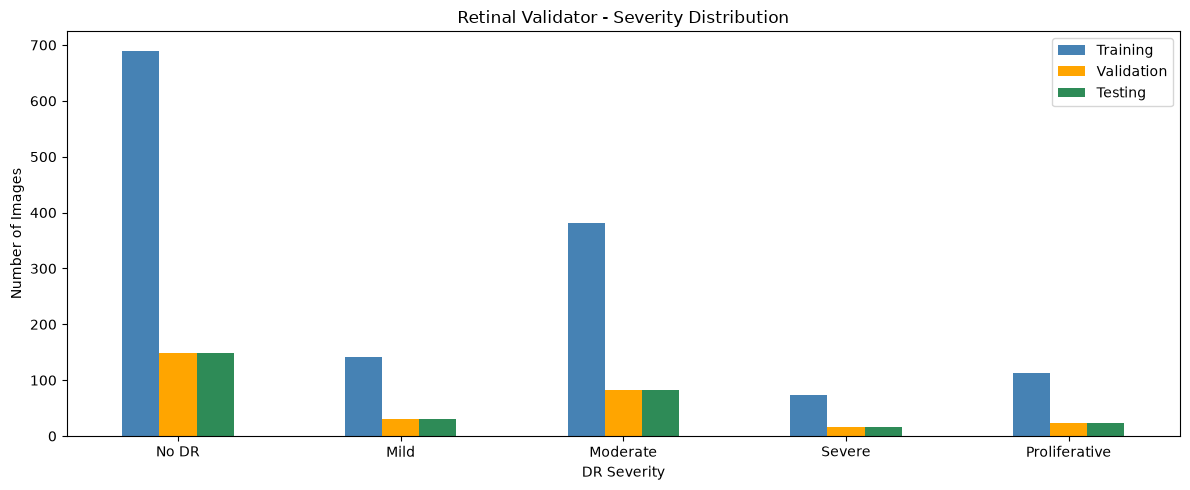

In [8]:
severity_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

distribution = pd.DataFrame({
    "Training": retinal_train_df["diagnosis"].value_counts(),
    "Validation": retinal_val_df["diagnosis"].value_counts(),
    "Testing": retinal_test_df["diagnosis"].value_counts()
}).reindex(range(5), fill_value=0)

distribution.index = severity_names

print(distribution)

distribution.plot(
    kind="bar",
    figsize=(12, 5),
    color=["steelblue", "orange", "seagreen"]
)

plt.title("Retinal Validator - Severity Distribution")
plt.ylabel("Number of Images")
plt.xlabel("DR Severity")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
(
    (cifar_train_images, cifar_train_labels),
    (cifar_test_images, cifar_test_labels)
) = tf.keras.datasets.cifar10.load_data()

cifar_train_labels = cifar_train_labels.flatten()
cifar_test_labels = cifar_test_labels.flatten()

print("CIFAR-10 Training Images:")
print(cifar_train_images.shape)

print("\nCIFAR-10 Testing Images:")
print(cifar_test_images.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1655s 10us/step
CIFAR-10 Training Images:
(50000, 32, 32, 3)

CIFAR-10 Testing Images:
(10000, 32, 32, 3)


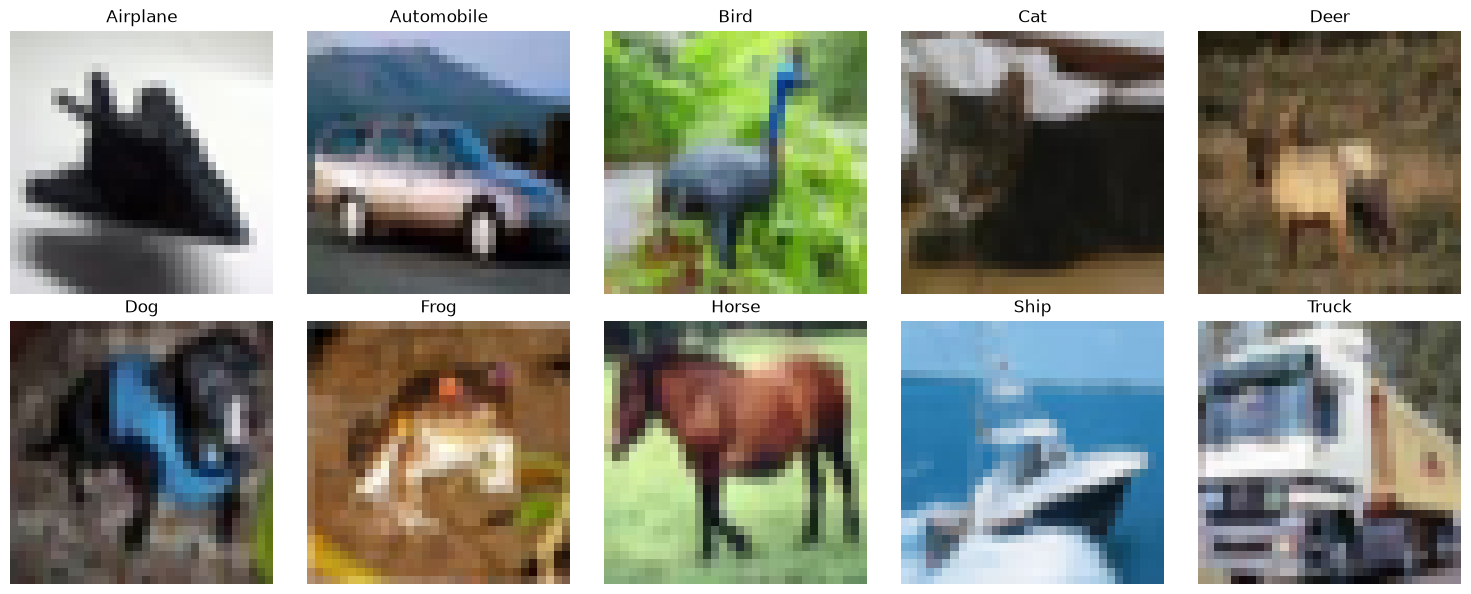

In [10]:
cifar_class_names = [
    "Airplane",
    "Automobile",
    "Bird",
    "Cat",
    "Deer",
    "Dog",
    "Frog",
    "Horse",
    "Ship",
    "Truck"
]

plt.figure(figsize=(15, 6))

for class_id in range(10):

    index = np.where(
        cifar_train_labels == class_id
    )[0][0]

    plt.subplot(2, 5, class_id + 1)

    plt.imshow(cifar_train_images[index])

    plt.title(cifar_class_names[class_id])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
rng = np.random.default_rng(SEED)

negative_train_indices = []
negative_val_indices = []
negative_test_indices = []

for class_id in range(10):

    train_indices = np.where(
        cifar_train_labels == class_id
    )[0]

    test_indices = np.where(
        cifar_test_labels == class_id
    )[0]

    train_selected = rng.choice(
        train_indices,
        size=170,
        replace=False
    )

    test_selected = rng.choice(
        test_indices,
        size=30,
        replace=False
    )

    negative_train_indices.extend(
        train_selected[:140]
    )

    negative_val_indices.extend(
        train_selected[140:]
    )

    negative_test_indices.extend(
        test_selected
    )

assert set(negative_train_indices).isdisjoint(
    negative_val_indices
)

print("Non-Retinal Training:", len(negative_train_indices))
print("Non-Retinal Validation:", len(negative_val_indices))
print("Non-Retinal Testing:", len(negative_test_indices))

Non-Retinal Training: 1400
Non-Retinal Validation: 300
Non-Retinal Testing: 300


In [12]:
def save_non_retinal_images(
    images,
    labels,
    indices,
    split_name,
    source_partition
):

    split_dir = NON_RETINAL_DIR / split_name

    split_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    records = []

    for index in indices:

        filename = (
            f"cifar10_{source_partition}_{index:05d}.png"
        )

        image_path = split_dir / filename

        Image.fromarray(
            images[index]
        ).save(image_path)

        records.append({
            "image_path": str(image_path),
            "label": 0,
            "class_name": "non_retinal",
            "source": "CIFAR10",
            "original_class": cifar_class_names[
                labels[index]
            ]
        })

    return pd.DataFrame(records)


non_retinal_train_df = save_non_retinal_images(
    cifar_train_images,
    cifar_train_labels,
    negative_train_indices,
    "train",
    "train"
)

non_retinal_val_df = save_non_retinal_images(
    cifar_train_images,
    cifar_train_labels,
    negative_val_indices,
    "validation",
    "train"
)

non_retinal_test_df = save_non_retinal_images(
    cifar_test_images,
    cifar_test_labels,
    negative_test_indices,
    "test",
    "test"
)

print("Non-retinal images saved successfully.")

print("Training:", len(non_retinal_train_df))
print("Validation:", len(non_retinal_val_df))
print("Testing:", len(non_retinal_test_df))

Non-retinal images saved successfully.
Training: 1400
Validation: 300
Testing: 300


In [13]:
def combine_datasets(retinal, non_retinal):

    columns = [
        "image_path",
        "label",
        "class_name",
        "source"
    ]

    combined = pd.concat(
        [
            retinal[columns],
            non_retinal[columns]
        ],
        ignore_index=True
    )

    combined = combined.sample(
        frac=1,
        random_state=SEED
    ).reset_index(drop=True)

    return combined


validator_train_df = combine_datasets(
    retinal_train_df,
    non_retinal_train_df
)

validator_val_df = combine_datasets(
    retinal_val_df,
    non_retinal_val_df
)

validator_test_df = combine_datasets(
    retinal_test_df,
    non_retinal_test_df
)

print("Training:", len(validator_train_df))
print("Validation:", len(validator_val_df))
print("Testing:", len(validator_test_df))

validator_train_df.head()

Training: 2800
Validation: 600
Testing: 600


,image_path,label,class_name,source
0,d:\AI-Powered-Diabetic-Retinopathy-System\ml-m...,1,retinal,APTOS2019
1,d:\AI-Powered-Diabetic-Retinopathy-System\ml-m...,1,retinal,APTOS2019
2,d:\AI-Powered-Diabetic-Retinopathy-System\ml-m...,0,non_retinal,CIFAR10
3,d:\AI-Powered-Diabetic-Retinopathy-System\ml-m...,1,retinal,APTOS2019
4,d:\AI-Powered-Diabetic-Retinopathy-System\ml-m...,0,non_retinal,CIFAR10


             Training  Validation  Testing  Total
class_name                                       
retinal          1400         300      300   2000
non_retinal      1400         300      300   2000

Total Dataset Size: 4000


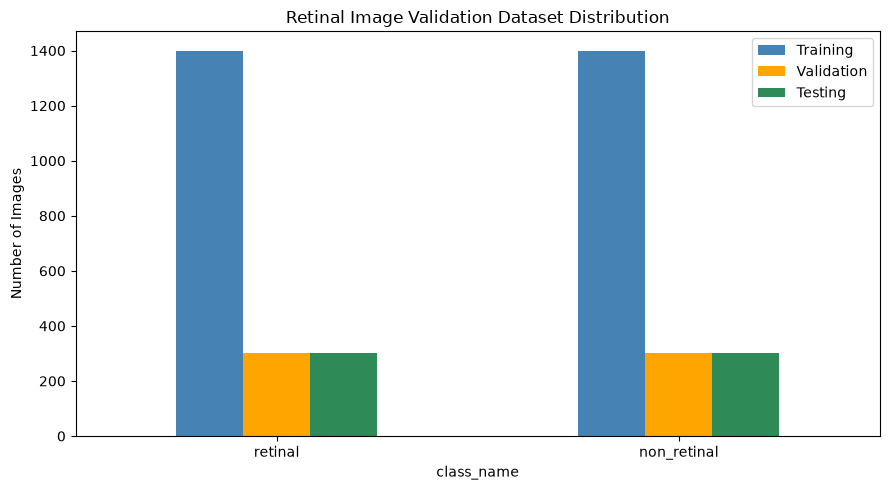

In [14]:
summary = pd.DataFrame({
    "Training": validator_train_df["class_name"].value_counts(),
    "Validation": validator_val_df["class_name"].value_counts(),
    "Testing": validator_test_df["class_name"].value_counts()
})

summary["Total"] = summary.sum(axis=1)

print(summary)

print("\nTotal Dataset Size:", summary["Total"].sum())

summary[["Training", "Validation", "Testing"]].plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange", "seagreen"]
)

plt.title("Retinal Image Validation Dataset Distribution")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

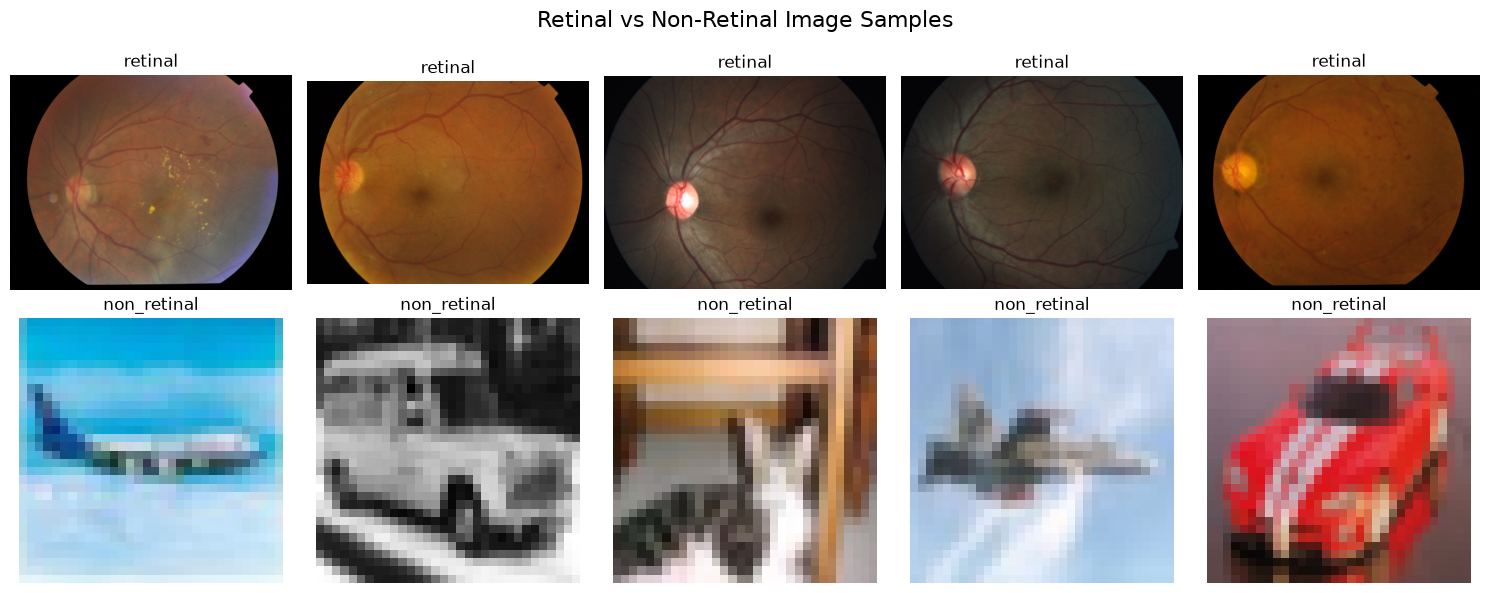

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for row_index, class_label in enumerate([1, 0]):

    samples = validator_train_df[
        validator_train_df["label"] == class_label
    ].sample(5, random_state=SEED)

    for col_index, (_, sample) in enumerate(
        samples.iterrows()
    ):

        with Image.open(sample["image_path"]) as image:
            axes[row_index, col_index].imshow(
                image.convert("RGB")
            )

        axes[row_index, col_index].set_title(
            sample["class_name"]
        )

        axes[row_index, col_index].axis("off")

plt.suptitle(
    "Retinal vs Non-Retinal Image Samples",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [16]:
def save_dataset_metadata(df, filename):

    df = df.copy()

    assert df["image_path"].apply(os.path.isfile).all()
    assert df["image_path"].is_unique

    df["image_path"] = df["image_path"].apply(
        lambda path: Path(path)
        .resolve()
        .relative_to(PROJECT_ROOT)
        .as_posix()
    )

    output_path = METADATA_DIR / filename

    df.to_csv(output_path, index=False)

    print("Saved:", output_path.name)


train_paths = set(validator_train_df["image_path"])
val_paths = set(validator_val_df["image_path"])
test_paths = set(validator_test_df["image_path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

save_dataset_metadata(
    validator_train_df,
    "train.csv"
)

save_dataset_metadata(
    validator_val_df,
    "validation.csv"
)

save_dataset_metadata(
    validator_test_df,
    "test.csv"
)

print("\nDataset metadata saved successfully.")

Saved: train.csv
Saved: validation.csv
Saved: test.csv

Dataset metadata saved successfully.


In [17]:
print("=" * 60)
print("RETINAL VALIDATION DATASET SUMMARY")
print("=" * 60)

for name, df in [
    ("Training", validator_train_df),
    ("Validation", validator_val_df),
    ("Testing", validator_test_df)
]:

    print(f"\n{name} Dataset")
    print("-" * 30)

    print("Total:", len(df))
    print("Retinal:", (df["label"] == 1).sum())
    print("Non-Retinal:", (df["label"] == 0).sum())

print("\nTotal Images:", (
    len(validator_train_df)
    + len(validator_val_df)
    + len(validator_test_df)
))

print("\nClass Mapping:")
print("0 -> Non-Retinal Image")
print("1 -> Retinal Fundus Image")

print("\nDataset preparation completed.")
print("=" * 60)

RETINAL VALIDATION DATASET SUMMARY

Training Dataset
------------------------------
Total: 2800
Retinal: 1400
Non-Retinal: 1400

Validation Dataset
------------------------------
Total: 600
Retinal: 300
Non-Retinal: 300

Testing Dataset
------------------------------
Total: 600
Retinal: 300
Non-Retinal: 300

Total Images: 4000

Class Mapping:
0 -> Non-Retinal Image
1 -> Retinal Fundus Image

Dataset preparation completed.
